# test 2 robot - Traffic Sign Detection with YOLOv8
SEE (YOLOv8 boxes) -> DECIDE (smoothed class -> command) -> ACT (serial to Arduino).

**Run from inside `archive/`** (the folder that contains `DATA/` and `labels.csv`). Run the cells top to bottom:

1. Setup -> 2. Crops -> 3. Backgrounds -> 4. Build dataset -> 5. Train -> 6. Evaluate -> 7. Live camera (local only)

**Training on a remote machine with no webcam?** Run everything except the live demo. Background cell A is optional (video upload), cell B (MIT) is enough to train. Take `best.pt` to your laptop or robot for the camera part.

The Kaggle dataset (tuanai, Traffic-Signs-Dataset) is classification-only (cropped sign images, no boxes),
so boxes are generated by pasting crops onto background photos (your own camera frames plus a MIT Indoor Scenes subset). Cite both datasets in your documentation.

## 1. Setup

In [1]:
!pip install -q ultralytics opencv-python-headless pyserial matplotlib

In [2]:
import csv, random, shutil, sys, tarfile, time, urllib.request
from collections import deque
from pathlib import Path

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt

CLASSES = ["no_entry", "go_left", "go_right", "go_straight", "zebra_crossing"]   # order = class id
CMD = {"no_entry": "S", "go_left": "L", "go_right": "R", "go_straight": "F", "zebra_crossing": "P"}
# S = stop, L = left, R = right, F = forward, P = pause ~2 s then continue
ROOT = Path("dataset")
SPLITS = {"train": 0.7, "val": 0.2, "test": 0.1}

# use the NVIDIA GPU if available, otherwise CPU
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Using device:", torch.cuda.get_device_name(0) if DEVICE == 0 else DEVICE)


def open_camera(index=0):
    """Open the webcam. Windows needs DSHOW/MSMF; first frames are often black, so warm up."""
    backends = [cv2.CAP_DSHOW, cv2.CAP_MSMF] if sys.platform == "win32" else [cv2.CAP_ANY]
    for be in backends:
        cap = cv2.VideoCapture(index, be)
        if cap.isOpened():
            for _ in range(10):
                cap.read()
            return cap
        cap.release()
    raise RuntimeError(f"Camera {index} did not open - try index 1, or close other apps using it")

Using device: NVIDIA RTX A5000


## 2. Pick the 5 classes from the dataset
Class IDs are looked up **by name in `labels.csv`** instead of hardcoded (the old IDs were wrong: 18 is a speed-limit sign, not "No entry").
Check the printout. If a match is wrong, set the right ID in `OVERRIDE` and rerun.
This cell deletes the old `crops/` and `dataset/` folders and rebuilds them (`backgrounds/` is not touched).

In [3]:
root = Path.cwd()
print("cwd:", root)
DATA = root / "DATA"
assert DATA.exists(), "DATA folder not found here - open this notebook from inside archive/"
IMG = {".jpg", ".jpeg", ".png", ".bmp", ".ppm", ".webp"}

for p in ("crops", "dataset"):
    shutil.rmtree(root / p, ignore_errors=True)

lab = next((p for p in (root / "labels.csv", DATA / "labels.csv", root.parent / "labels.csv") if p.exists()), None)
assert lab, "labels.csv not found next to DATA/"
names = {int(r["ClassId"]): r["Name"].strip() for r in csv.DictReader(open(lab, encoding="utf-8-sig"))}


def find_ids(tiers):
    # a tier starting with "=" is an exact (case-insensitive) name match, otherwise a substring match
    for t in tiers:
        key = t.lstrip("=")
        hits = sorted(i for i, n in names.items()
                      if (n.lower() == key if t.startswith("=") else key in n.lower()))
        if hits:
            return hits
    return []


WANT = {
    "no_entry":       ["=no entry"],
    "go_left":        ["=go left"],
    "go_right":       ["=go right"],
    "go_straight":    ["=go straight"],
    "zebra_crossing": ["zebra", "pedestrian", "crossing"],
}
OVERRIDE = {}   # e.g. {"zebra_crossing": 35} if the automatic match below is wrong

CLASS_IDS = {}
for c, tiers in WANT.items():
    hits = find_ids(tiers)
    print(f"{c:15s} matches: {[(i, names[i]) for i in hits]}")
    if hits:
        CLASS_IDS[c] = hits[0]
CLASS_IDS.update(OVERRIDE)

missing = [c for c in WANT if c not in CLASS_IDS]
if missing:
    print("\nNo match for:", missing)
    print("All labels:", names)
    raise SystemExit("Set OVERRIDE with the right ids and rerun this cell.")

for c, cid in CLASS_IDS.items():
    out = root / "crops" / c
    out.mkdir(parents=True)
    n = 0
    for d in DATA.iterdir():
        if d.is_dir() and d.name.isdigit() and int(d.name) == cid:
            for f in d.rglob("*"):
                if f.is_file() and f.suffix.lower() in IMG:
                    shutil.copy(f, out / f"{d.name}_{f.name}")
                    n += 1
    print(f"{c:15s} id {cid:2d} ({names[cid]}): {n} images" + ("" if n >= 150 else "   <-- low"))

cwd: /home/marcdextersael/computer_vision/archive
no_entry        matches: [(18, 'No entry')]
go_left         matches: [(22, 'Go Left')]
go_right        matches: [(24, 'Go Right')]
go_straight     matches: [(21, 'Go straight')]
zebra_crossing  matches: [(35, 'Zebra Crossing')]
no_entry        id 18 (No entry): 210 images
go_left         id 22 (Go Left): 31 images   <-- low
go_right        id 24 (Go Right): 108 images   <-- low
go_straight     id 21 (Go straight): 28 images   <-- low
zebra_crossing  id 35 (Zebra Crossing): 189 images


### Background photos
Backgrounds come from two sources. **Use both** (you need at least 50 in total, 100+ is better):

- **A. Your own camera** (best, optional): frames from a video of your real test area with no signs in view. No webcam needed, just upload a video.
- **B. MIT Indoor Scenes** (supplement): a few hundred indoor photos (Quattoni & Torralba, CVPR 2009). **Cite it in your documentation.**

Files are named `cam_*.jpg` and `mit_*.jpg` so the dataset cell can split each source separately.
Both cells can be skipped if `backgrounds/` already has enough photos. Both cells run fine on a remote machine.

**A. (Optional) Extract frames from a video.**
Record 1-2 minutes of your track or room with no signs in view (phone or robot camera), upload it next to the notebook, and set `VIDEO`.
If the file isn't there, this cell just skips, so you can train on MIT backgrounds alone.

In [4]:
VIDEO = "bg_video.mp4"      # your uploaded video (optional)
EVERY_SEC = 0.5

BG = Path("backgrounds")
BG.mkdir(exist_ok=True)

if len(list(BG.glob("cam_*.jpg"))) >= 30:
    print("camera backgrounds already in backgrounds/ - skipping")
elif not Path(VIDEO).exists():
    print(f"{VIDEO} not found - skipping (training on MIT backgrounds only)")
else:
    cap = cv2.VideoCapture(VIDEO)
    assert cap.isOpened(), f"Could not open {VIDEO}"
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    step = max(1, int(fps * EVERY_SEC))
    i = saved = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if i % step == 0:
            cv2.imwrite(str(BG / f"cam_{saved:03d}.jpg"), cv2.resize(frame, (640, 480)))
            saved += 1
        i += 1
    cap.release()
    print(saved, "camera backgrounds saved")

bg_video.mp4 not found - skipping (training on MIT backgrounds only)


**B. Get MIT Indoor Scenes backgrounds from the Kaggle copy.**
Downloads `itsahmad/indoor-scenes-cvpr-2019` with `kagglehub` onto the machine running the notebook (the remote/HPC, not your laptop), then keeps only `PER_CAT` photos from each category in `MIT_CATS`, resized to 640x480.
Needs Kaggle credentials (`~/.kaggle/kaggle.json`, or set `KAGGLE_USERNAME` / `KAGGLE_KEY` in the cell). If the compute node has no internet, run this cell from the login node.
Category names are matched ignoring case/underscores. If some are not found, edit `MIT_CATS` using the printed `folders found` list. **Cite MIT Indoor Scenes (Quattoni & Torralba) and the Kaggle upload in your documentation.**

In [5]:
import importlib, subprocess, sys, os, re, random
from pathlib import Path
import cv2

# 1) install kagglehub into THIS kernel's environment
try:
    import kagglehub
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

# 2) credentials: read kaggle.json from the notebook folder (falls back to ~/.kaggle/kaggle.json)
import json
for kj in (Path("kaggle.json"), Path.cwd().parent / "kaggle.json", Path.home() / ".kaggle" / "kaggle.json"):
    if kj.exists():
        creds = json.load(open(kj))
        os.environ["KAGGLE_USERNAME"] = creds["username"]
        os.environ["KAGGLE_KEY"] = creds["key"]
        print("using credentials from", kj.resolve())
        break
else:
    print("WARNING: kaggle.json not found - put it next to this notebook (cwd:", Path.cwd(), ")")
# os.environ["KAGGLEHUB_CACHE"] = "/path/with/space/kagglehub"   # optional, if home quota is small

MIT_CATS = ["corridor", "classroom", "bedroom", "livingroom", "garage",
            "office", "kitchen", "meeting_room", "lobby", "stairscase"]
PER_CAT = 20
EXTS = {".jpg", ".jpeg", ".png", ".bmp"}


def norm(s):
    return re.sub(r"[^a-z0-9]", "", s.lower())      # "Living_Room" -> "livingroom"


def fetch_mit_backgrounds(cats=MIT_CATS, per_cat=PER_CAT, out_dir="backgrounds"):
    out = Path(out_dir)
    out.mkdir(exist_ok=True)
    if len(list(out.glob("mit_*.jpg"))) >= per_cat * len(cats) // 2:
        print("MIT backgrounds already in", out, "- skipping")
        return

    try:
        src = Path(kagglehub.dataset_download("itsahmad/indoor-scenes-cvpr-2019"))
    except Exception as e:
        raise RuntimeError(
            f"Kaggle download failed: {type(e).__name__}: {e}\n"
            "401/403 -> check KAGGLE_USERNAME/KAGGLE_KEY or ~/.kaggle/kaggle.json\n"
            "connection/timeout -> compute node may have no internet; run this cell from the login node"
        ) from e
    print("dataset at:", src)

    # group images by their parent folder name (= scene category)
    by_cat = {}
    for p in src.rglob("*"):
        if p.is_file() and p.suffix.lower() in EXTS:
            by_cat.setdefault(norm(p.parent.name), []).append(p)
    print(f"{sum(len(v) for v in by_cat.values())} images in {len(by_cat)} folders")
    print("folders found:", sorted(by_cat)[:80])
    assert by_cat, f"No images found under {src} - look at the folder structure manually"

    wanted = {c: norm(c) for c in cats}
    hit = {c: k for c, k in wanted.items() if k in by_cat}
    miss = [c for c in cats if c not in hit]
    if miss:
        print("not found (edit MIT_CATS to match 'folders found' above):", miss)
    if not hit:                                   # nothing matched: fall back to random folders
        print("No MIT_CATS matched - sampling from the folders that do exist")
        picks = random.sample(sorted(by_cat), k=min(10, len(by_cat)))
        hit = {k: k for k in picks}

    count = {}
    for c, k in hit.items():
        files = by_cat[k][:]
        random.shuffle(files)
        n = 0
        for p in files:
            if n >= per_cat:
                break
            im = cv2.imread(str(p))
            if im is None:
                continue
            cv2.imwrite(str(out / f"mit_{c}_{n:03d}.jpg"), cv2.resize(im, (640, 480)))
            n += 1
        count[c] = n
    print(count)
    print(len(list(out.glob("mit_*.jpg"))), "MIT backgrounds saved")


fetch_mit_backgrounds()


using credentials from /home/marcdextersael/computer_vision/archive/kaggle.json
Resuming download from 279969792 bytes (2228312512 bytes left)...
Resuming download to /home/marcdextersael/.cache/kagglehub/datasets/itsahmad/indoor-scenes-cvpr-2019/1.archive (279969792/2508282304) bytes left.


100%|██████████| 2.34G/2.34G [01:15<00:00, 29.4MB/s]

Extracting files...


dataset at: /home/marcdextersael/.cache/kagglehub/datasets/itsahmad/indoor-scenes-cvpr-2019/versions/1
15620 images in 67 folders
folders found: ['airportinside', 'artstudio', 'auditorium', 'bakery', 'bar', 'bathroom', 'bedroom', 'bookstore', 'bowling', 'buffet', 'casino', 'childrenroom', 'churchinside', 'classroom', 'cloister', 'closet', 'clothingstore', 'computerroom', 'concerthall', 'corridor', 'deli', 'dentaloffice', 'diningroom', 'elevator', 'fastfoodrestaurant', 'florist', 'gameroom', 'garage', 'greenhouse', 'grocerystore', 'gym', 'hairsalon', 'hospitalroom', 'insidebus', 'insidesubway', 'jewelleryshop', 'kindergarden', 'kitchen', 'laboratorywet', 'laundromat', 'library', 'livingroom', 'lobby', 'lockerroom', 'mall', 'meetingroom', 'movietheater', 'museum', 'nursery', 'office', 'operatingroom', 'pantry', 'poolinside', 'prisoncell', 'restaurant', 'restaurantkitchen', 'shoeshop', 'stairscase', 'studiomusic', 'subway', 'toystore', 'trainstation', 'tvstudio', 'videostore', 'waitingroo

**C. Remove backgrounds that contain real signs.**
A real traffic sign in a "background" teaches the model that signs are not signs.
This runs the standard COCO model over the `mit_*` photos and deletes any with a stop sign or traffic light.
Then look at the contact sheet and delete anything else suspicious by hand (a sign, poster with a sign, or a screen showing one).
Your own `cam_*` photos are never touched.

removed 1 of 200 MIT photos with a sign or traffic light


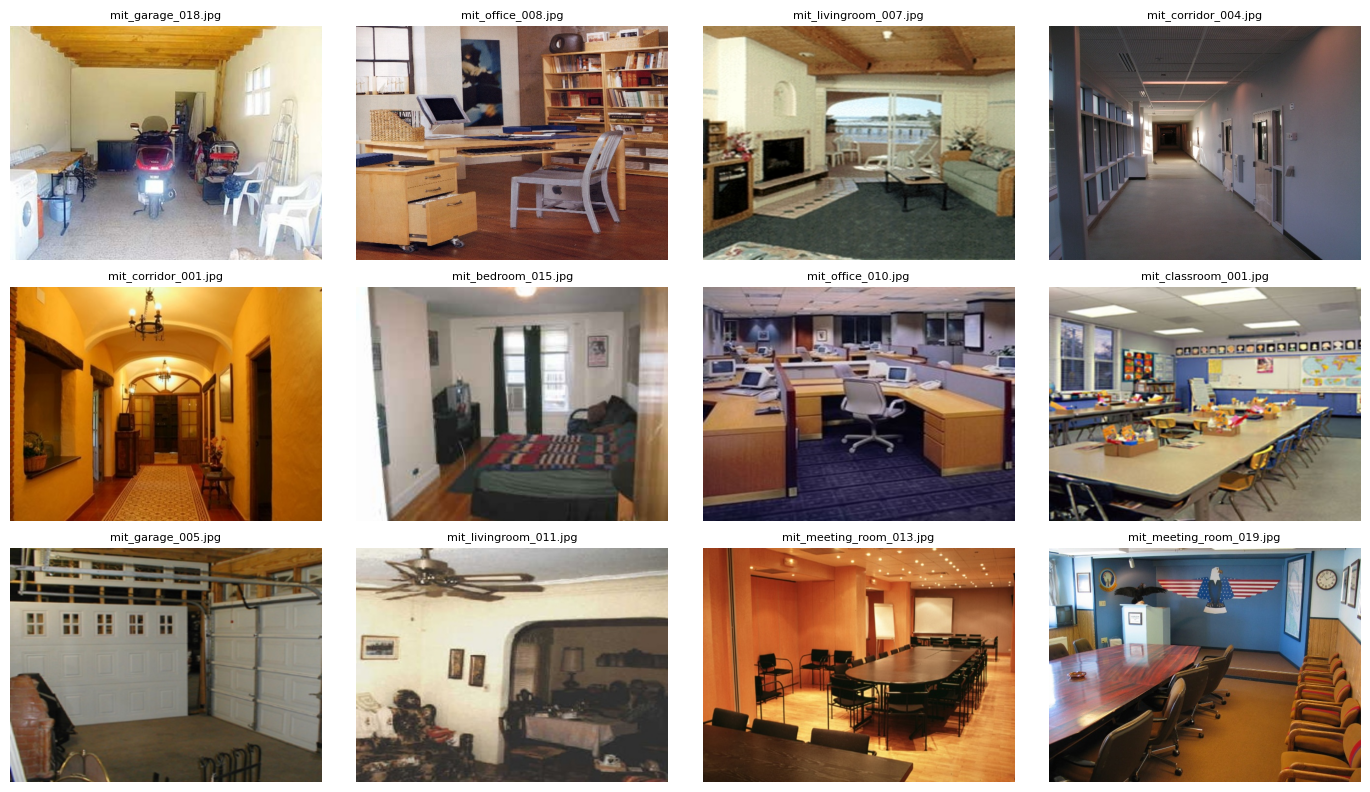

In [6]:
from ultralytics import YOLO

coco = YOLO("yolov8n.pt")            # COCO: 9 = traffic light, 11 = stop sign
mit = sorted(Path("backgrounds").glob("mit_*.jpg"))
removed = 0
for p in mit:
    r = coco.predict(str(p), conf=0.25, classes=[9, 11], device=DEVICE, verbose=False)[0]
    if len(r.boxes):
        p.unlink()
        removed += 1
print(f"removed {removed} of {len(mit)} MIT photos with a sign or traffic light")

shown = random.sample(sorted(Path("backgrounds").glob("*.jpg")), k=min(12, len(list(Path("backgrounds").glob("*.jpg")))))
fig, axes = plt.subplots(3, 4, figsize=(14, 8))
for ax in axes.flat:
    ax.axis("off")
for ax, p in zip(axes.flat, shown):
    ax.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB))
    ax.set_title(p.name, fontsize=8)
plt.tight_layout()
plt.show()

## 3. Build the dataset (synthetic boxes)
Pastes sign crops onto background photos and writes YOLO labels automatically.
Crops and backgrounds are split **before** generation (each background source separately), so no train/test leakage and your own camera frames also appear in the test split.
About 10% of the images contain **no sign** (empty label file) so the model learns what "nothing" looks like and gives fewer false detections.

In [7]:
def split_files(files):
    files = list(files)
    random.shuffle(files)
    n = len(files)
    a, b = int(n * 0.7), int(n * 0.9)
    return {"train": files[:a], "val": files[a:b], "test": files[b:]}


def split_backgrounds(bgs):
    # split each source (cam_ / mit_) on its own so your own camera frames land in train, val AND test
    out = {"train": [], "val": [], "test": []}
    for prefix in ("cam_", "mit_"):
        part = split_files(p for p in bgs if p.name.startswith(prefix))
        for sp in out:
            out[sp] += part[sp]
    other = split_files(p for p in bgs if not p.name.startswith(("cam_", "mit_")))
    for sp in out:
        out[sp] += other[sp]
    return out


def paste(bg, crop, rects):
    # paste crop at a random non-overlapping spot; return normalized YOLO box or None
    H, W = bg.shape[:2]
    for _ in range(10):
        w = int(W * random.uniform(0.08, 0.30))
        h = int(w * crop.shape[0] / crop.shape[1])
        if h < 8 or h >= H or w >= W:
            continue
        x, y = random.randint(0, W - w), random.randint(0, H - h)
        if any(x < rx + rw and rx < x + w and y < ry + rh and ry < y + h
               for rx, ry, rw, rh in rects):
            continue
        c = cv2.resize(crop, (w, h))
        c = cv2.convertScaleAbs(c, alpha=random.uniform(0.6, 1.3),
                                beta=random.uniform(-30, 30))
        if random.random() < 0.3:
            c = cv2.GaussianBlur(c, (5, 5), 0)
        bg[y:y + h, x:x + w] = c
        rects.append((x, y, w, h))
        return (x + w / 2) / W, (y + h / 2) / H, w / W, h / H
    return None


def synth(crops_dir="crops", bg_dir="backgrounds", n=1500, neg_frac=0.1):
    random.seed(0)
    crops = {c: sorted((Path(crops_dir) / c).glob("*.*")) for c in CLASSES}
    for c, f in crops.items():
        if not f:
            sys.exit(f"No images in {crops_dir}/{c} - run the crops cell first")
    bgs = sorted(Path(bg_dir).glob("*.*"))
    bg_split = split_backgrounds(bgs)
    crop_split = {c: split_files(f) for c, f in crops.items()}

    for sp, ratio in SPLITS.items():
        if not bg_split[sp]:
            sys.exit("Need more background photos (50+).")
        (ROOT / "images" / sp).mkdir(parents=True, exist_ok=True)
        (ROOT / "labels" / sp).mkdir(parents=True, exist_ok=True)
        for i in range(int(n * ratio)):
            bg = cv2.imread(str(random.choice(bg_split[sp])))
            if bg is None:
                continue
            bg = cv2.resize(bg, (640, 480))
            rects, lines = [], []
            n_signs = 0 if random.random() < neg_frac else random.choice([1, 1, 2])
            for _ in range(n_signs):
                cid = random.randrange(len(CLASSES))
                pool = crop_split[CLASSES[cid]][sp]
                if not pool:
                    continue
                crop = cv2.imread(str(random.choice(pool)))
                if crop is None:
                    continue
                box = paste(bg, crop, rects)
                if box:
                    lines.append(f"{cid} " + " ".join(f"{v:.6f}" for v in box))
            if n_signs and not lines:
                continue
            cv2.imwrite(str(ROOT / "images" / sp / f"{i:05d}.jpg"), bg)
            (ROOT / "labels" / sp / f"{i:05d}.txt").write_text("\n".join(lines))

    names_yaml = "\n".join(f"  {i}: {c}" for i, c in enumerate(CLASSES))
    (ROOT / "data.yaml").write_text(
        f"path: {ROOT.resolve().as_posix()}\ntrain: images/train\nval: images/val\n"
        f"test: images/test\nnames:\n{names_yaml}\n")
    print("Done. Dataset in", ROOT.resolve())

In [8]:
n_cam = len(list(Path("backgrounds").glob("cam_*.jpg")))
n_mit = len(list(Path("backgrounds").glob("mit_*.jpg")))
print(f"backgrounds: {n_cam} camera + {n_mit} MIT")
assert n_cam + n_mit >= 50, "Need 50+ background photos - run the background cells (A and/or B)"
shutil.rmtree(ROOT, ignore_errors=True)
synth()
for sp in SPLITS:
    print(sp, len(list((ROOT / "images" / sp).glob("*.jpg"))), "images")

backgrounds: 0 camera + 199 MIT
Done. Dataset in /home/marcdextersael/computer_vision/archive/dataset
train 1050 images
val 300 images
test 150 images


### Sanity check: verify the boxes look right

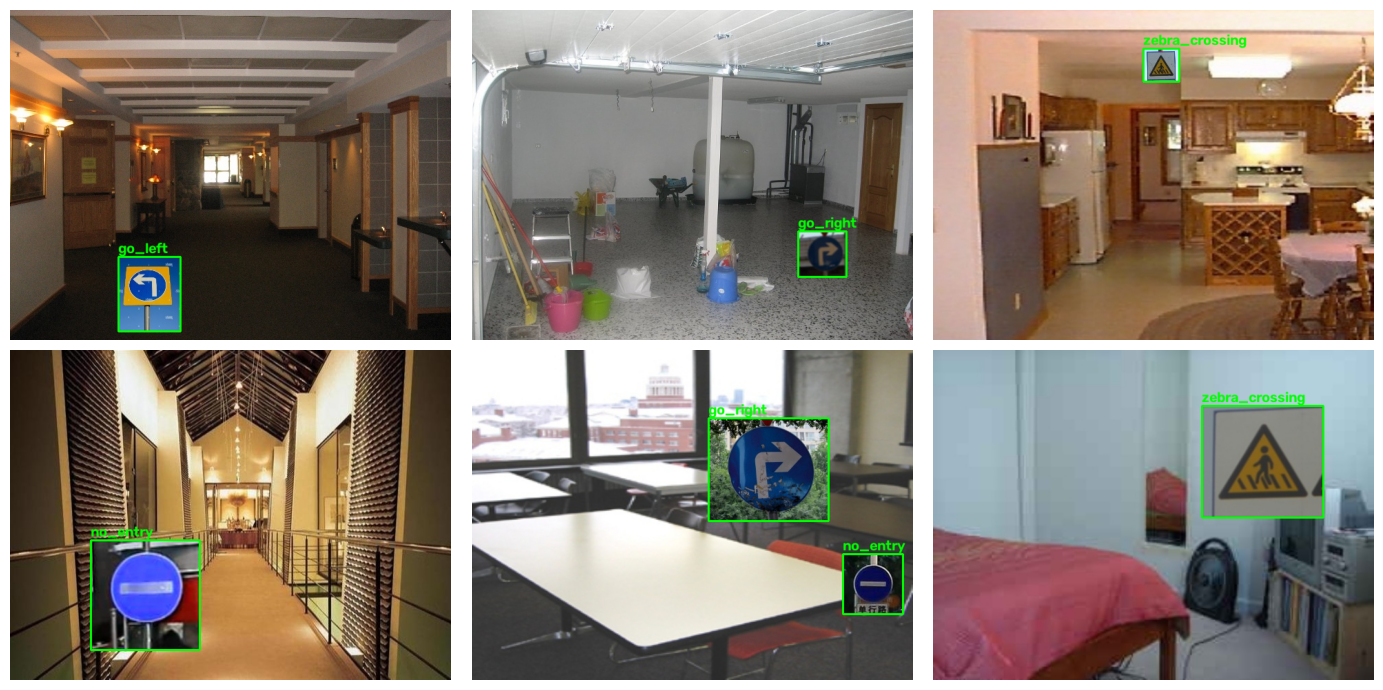

In [9]:
imgs = sorted((ROOT / "images" / "train").glob("*.jpg"))[:6]
assert imgs, "No generated images - run the dataset cell first"

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax in axes.flat:
    ax.axis("off")
for ax, p in zip(axes.flat, imgs):
    im = cv2.imread(str(p))
    H, W = im.shape[:2]
    for line in (ROOT / "labels" / "train" / f"{p.stem}.txt").read_text().splitlines():
        cid, cx, cy, w, h = line.split()
        cid = int(cid)
        cx, cy, w, h = float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
        p1 = int(cx - w / 2), int(cy - h / 2)
        p2 = int(cx + w / 2), int(cy + h / 2)
        cv2.rectangle(im, p1, p2, (0, 255, 0), 2)
        cv2.putText(im, CLASSES[cid], (p1[0], max(p1[1] - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
plt.tight_layout()
plt.show()

## 4. Train
`fliplr=0` is important: flipping turns left into right.
`EPOCHS = 30` is enough for a first test. On CPU this can take a while; raise it later for the final run.

In [10]:
from ultralytics import YOLO

EPOCHS = 30
assert (ROOT / "data.yaml").exists(), "Run the dataset cell first"

model = YOLO("yolov8n.pt")
model.train(
    data=str((ROOT / "data.yaml").resolve()),
    epochs=EPOCHS,
    imgsz=640,
    fliplr=0.0,
    device=DEVICE,
    project=str(Path("runs").resolve()),
    name="signs",
    exist_ok=True,
)

Ultralytics 8.4.171 🚀 Python-3.11.15 torch-2.5.1+cu121 CUDA:0 (NVIDIA RTX A5000, 24112MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/marcdextersael/computer_vision/archive/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=signs, nbs=64, nms=N

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x75ac15d722d0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

In [11]:
def find_weights():
    found = list(Path("runs").rglob("best.pt"))
    if not found:
        raise FileNotFoundError("No best.pt under runs/ - train first")
    return str(max(found, key=lambda p: p.stat().st_mtime))


WEIGHTS = find_weights()
print("Using weights:", WEIGHTS)

shutil.copy(WEIGHTS, "best.pt")
print("Copied to best.pt - download this one file")

Using weights: runs/signs/weights/best.pt
Copied to best.pt - download this one file


## 5. Evaluate on the test split
Prints mAP, precision, recall and saves `confusion_matrix.png` in the run folder.

Ultralytics 8.4.171 🚀 Python-3.11.15 torch-2.5.1+cu121 CUDA:0 (NVIDIA RTX A5000, 24112MiB)
Model summary (fused): 72 layers, 3,006,623 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2137.9±351.1 MB/s, size: 84.3 KB)
val: Scanning /home/marcdextersael/computer_vision/archive/dataset/labels/test... 150 images, 17 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 150/150 2.0Kit/s 0.1s
val: New cache created: /home/marcdextersael/computer_vision/archive/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 4.9it/s 2.0s.2ss
                   all        150        182      0.998          1      0.995      0.994
              no_entry         33         36      0.998          1      0.995      0.991
               go_left         36         40      0.999          1      0.995      0.995
              go_right         33         35      0.998          1      0.995      0.995
  

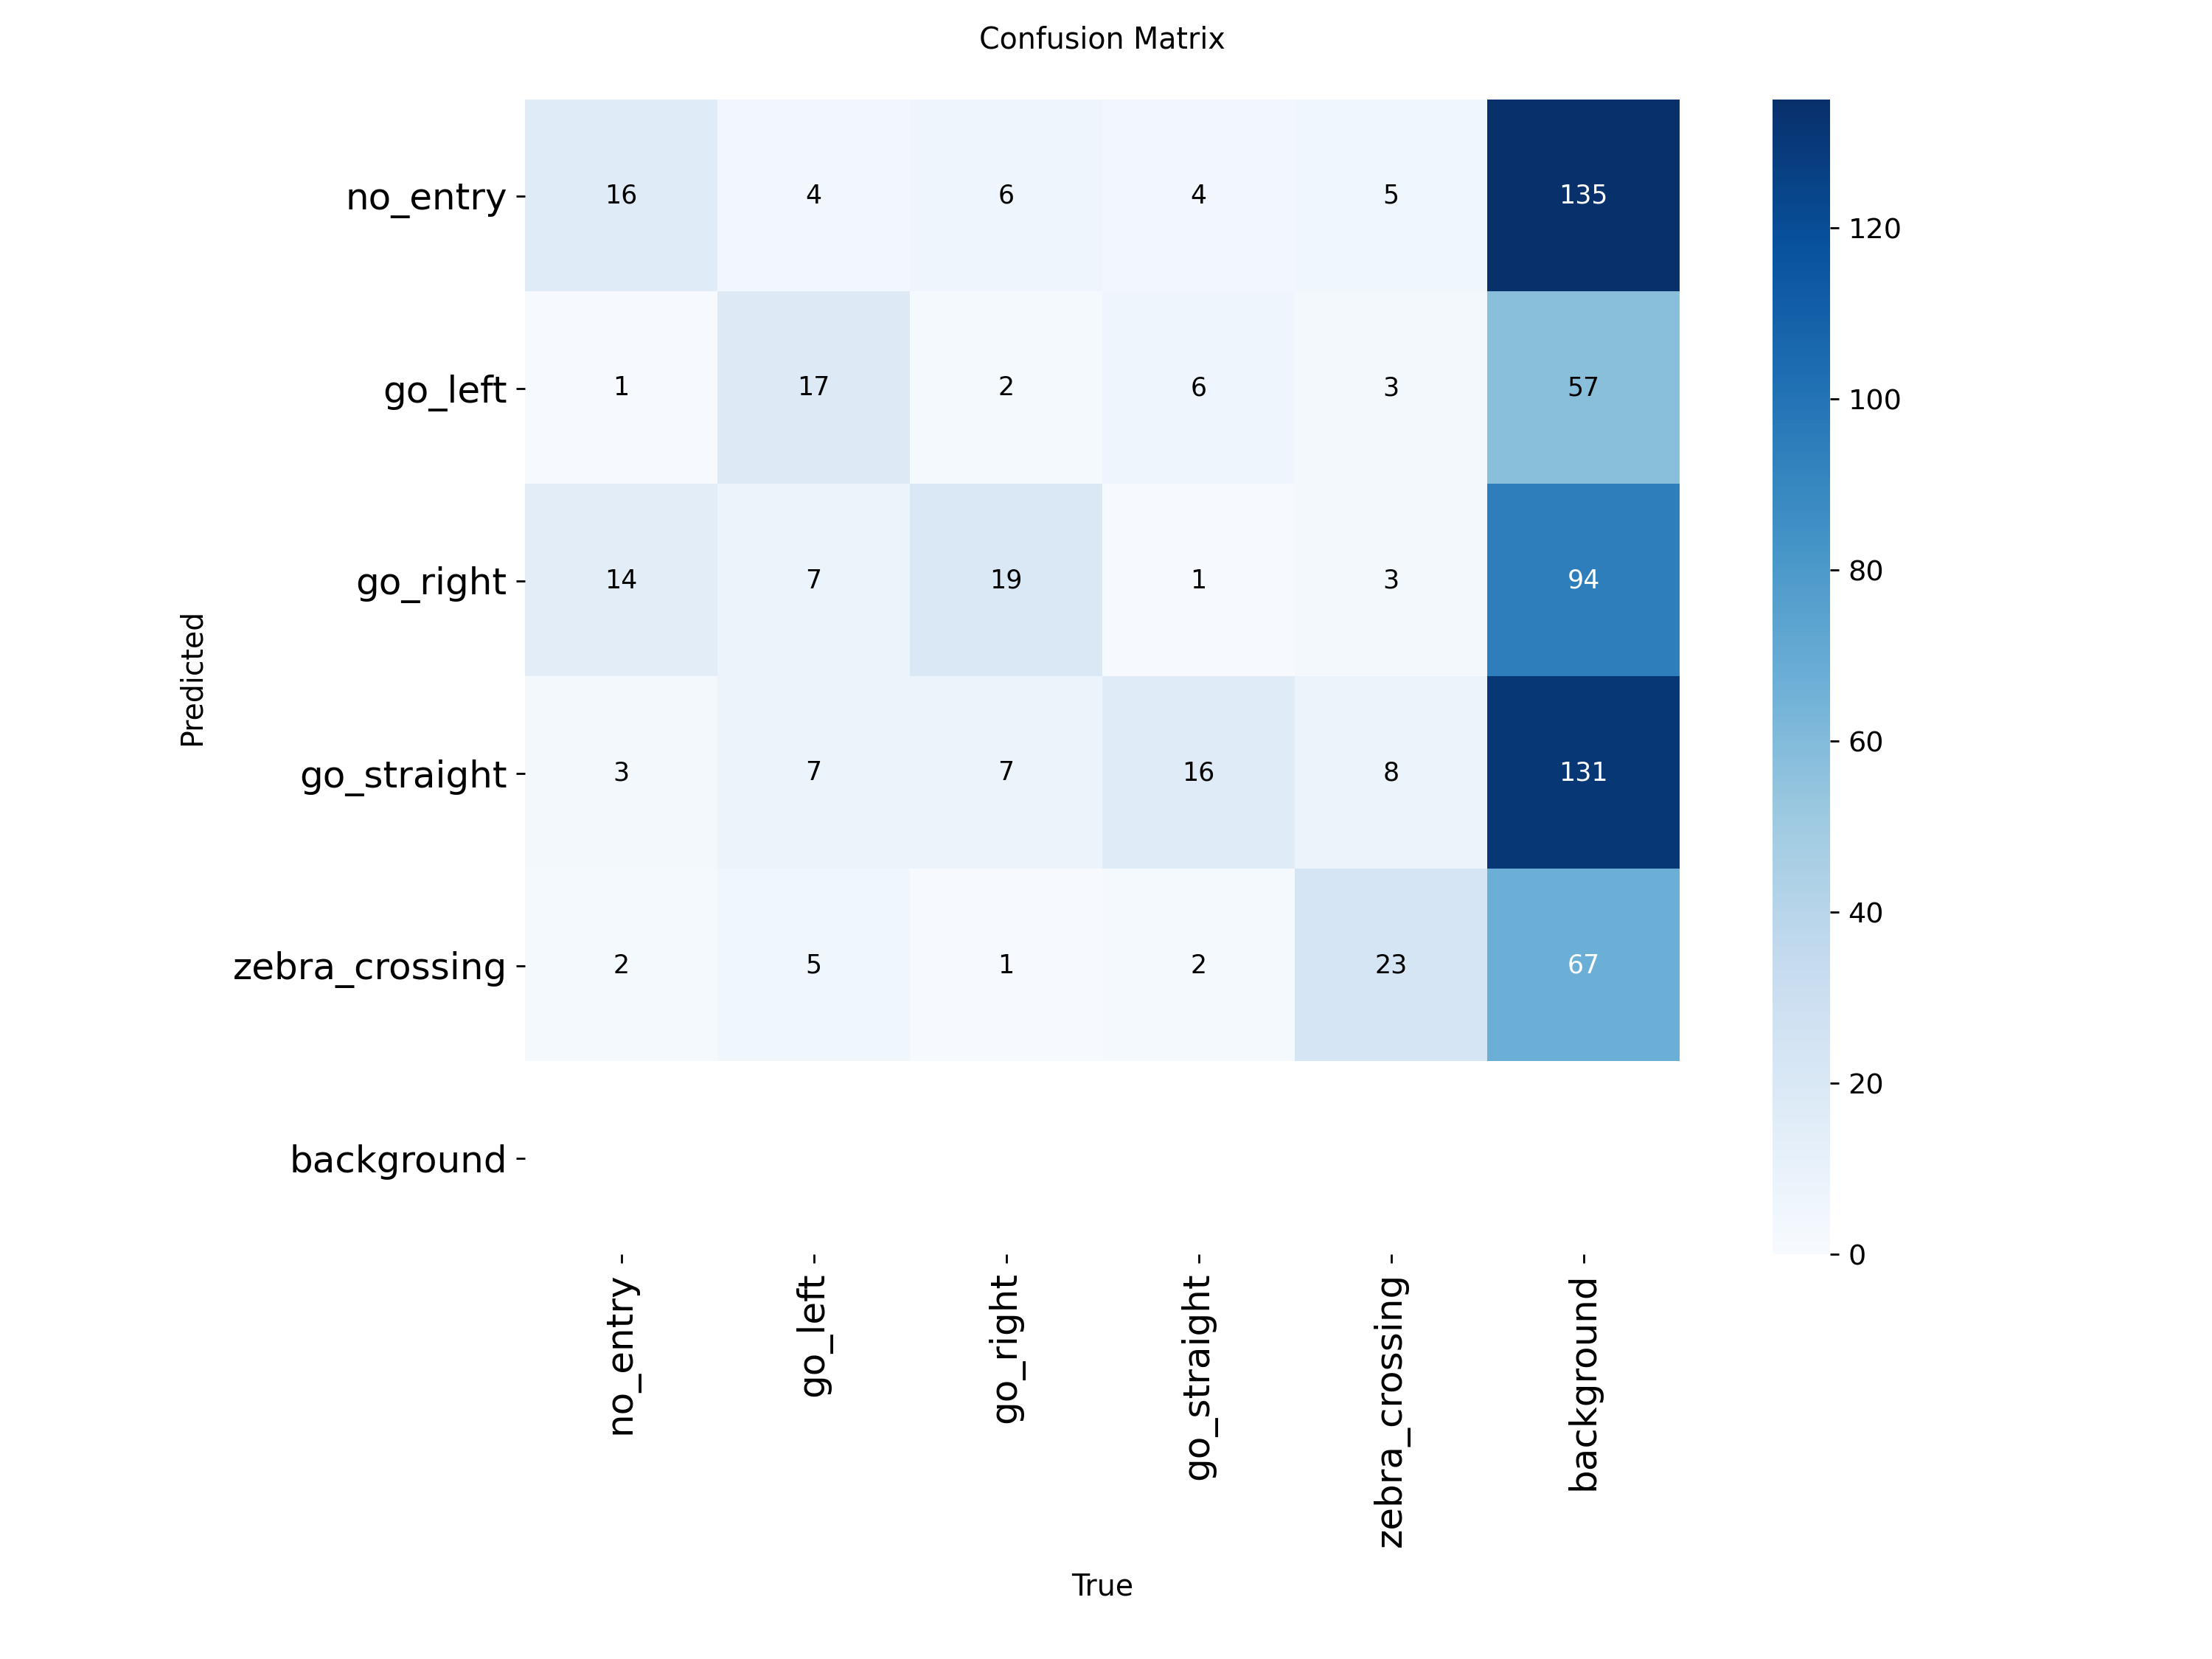

In [12]:
from IPython.display import Image, display

best = YOLO(WEIGHTS)
r = best.val(data=str((ROOT / "data.yaml").resolve()), split="test", plots=True, device=DEVICE)
print(f"mAP50: {r.box.map50:.3f} | mAP50-95: {r.box.map:.3f} | "
      f"precision: {r.box.mp:.3f} | recall: {r.box.mr:.3f}")
print("Saved in:", r.save_dir)

cm = Path(r.save_dir) / "confusion_matrix.png"
if cm.exists():
    display(Image(filename=str(cm)))

### Predict on test images (boxes + confidence)

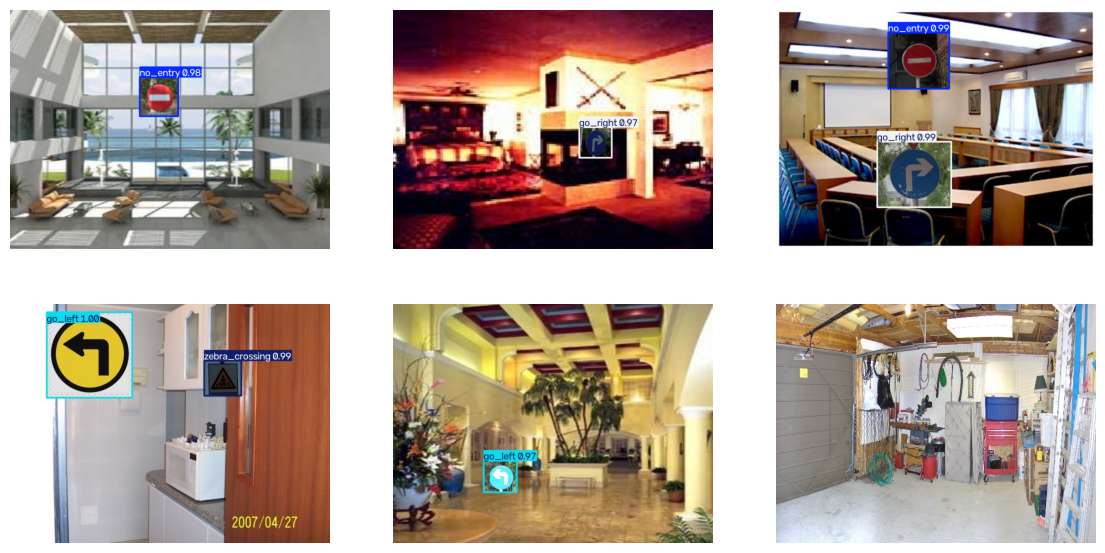

In [13]:
test_imgs = sorted((ROOT / "images" / "test").glob("*.jpg"))[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax in axes.flat:
    ax.axis("off")
for ax, p in zip(axes.flat, test_imgs):
    res = best.predict(str(p), conf=0.5, device=DEVICE, verbose=False)[0]
    ax.imshow(cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB))
plt.show()

## 6. Live demo + decision logic (SEE -> DECIDE -> ACT)
- Acts on the largest (closest) sign.
- A command is sent only if the same class is seen for `SMOOTH` consecutive frames at confidence >= `CONF`.
- Once no sign has been seen for `SMOOTH` frames, the same sign can trigger again.
- Keys: `q` quit, `x` emergency stop (toggle). The camera is always released, even if something crashes.
- `PORT = None` just prints commands. Set it (e.g. `"COM3"` or `"/dev/ttyUSB0"`) to send them to the Arduino.
- Hold up a printed sign or a phone screen. Do not mirror the image: flipping swaps left and right.
- **Skip this section on a remote/headless machine.** Needs a local Jupyter (opens a webcam window). It will not work in Colab. If the window freezes on Mac, run the same code as a `.py` file.

In [14]:
CONF, SMOOTH, CAM, PORT = 0.6, 4, 0, None


def live(weights=None, cam=CAM, port=PORT, conf=CONF, smooth=SMOOTH):
    model = YOLO(weights or find_weights())
    ser = None
    if port:
        import serial
        ser = serial.Serial(port, 115200, timeout=0.1)

    def send(c):
        print("CMD", c)
        if ser:
            ser.write(c.encode())

    cap = open_camera(cam)
    hist = deque(maxlen=smooth)
    last, estop = None, False

    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            r = model.predict(frame, conf=conf, device=DEVICE, verbose=False)[0]
            label = None
            if len(r.boxes):
                b = max(r.boxes, key=lambda b: float(b.xywh[0][2] * b.xywh[0][3]))
                label = model.names[int(b.cls[0])]
            hist.append(label)

            if len(hist) == hist.maxlen:
                if not estop and hist[0] in CMD and len(set(hist)) == 1:
                    cmd = CMD[hist[0]]
                    if cmd != last:
                        send(cmd)
                        last = cmd
                elif all(h is None for h in hist):
                    last = None   # sign gone -> the next sign can trigger again

            out = r.plot()
            cv2.putText(out, f"cmd: {'ESTOP' if estop else last}", (10, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 255), 2)
            cv2.imshow("signs (q quit, x estop)", out)

            k = cv2.waitKey(1) & 0xFF
            if k == ord("x"):
                estop = not estop
                if estop:
                    send("S")
                    last = "S"
            elif k == ord("q"):
                break
    finally:
        send("S")
        cap.release()
        cv2.destroyAllWindows()
        cv2.waitKey(1)
        if ser:
            ser.close()

In [15]:
# LOCAL ONLY (needs a webcam). Uncomment on your laptop/robot after copying best.pt next to this notebook.
# live("best.pt")